# Challenge Books to Scrape + Open Library

Notebook simple para resolver el challenge **sin bonus**, usando:

- `requests`
- `BeautifulSoup`
- `sqlite3`
- `pandas`

## Qué hace
1. Scrapea **todas las categorías** y **todos los libros** de Books to Scrape.
2. Busca cada libro en **Open Library** para obtener autor y enriquecerlo.
3. Crea la base SQLite desde cero.
4. Inserta categorías, libros, autores y relación muchos a muchos.
5. Ejecuta 5 consultas pedidas.
6. Mide una consulta antes y después de crear un índice.



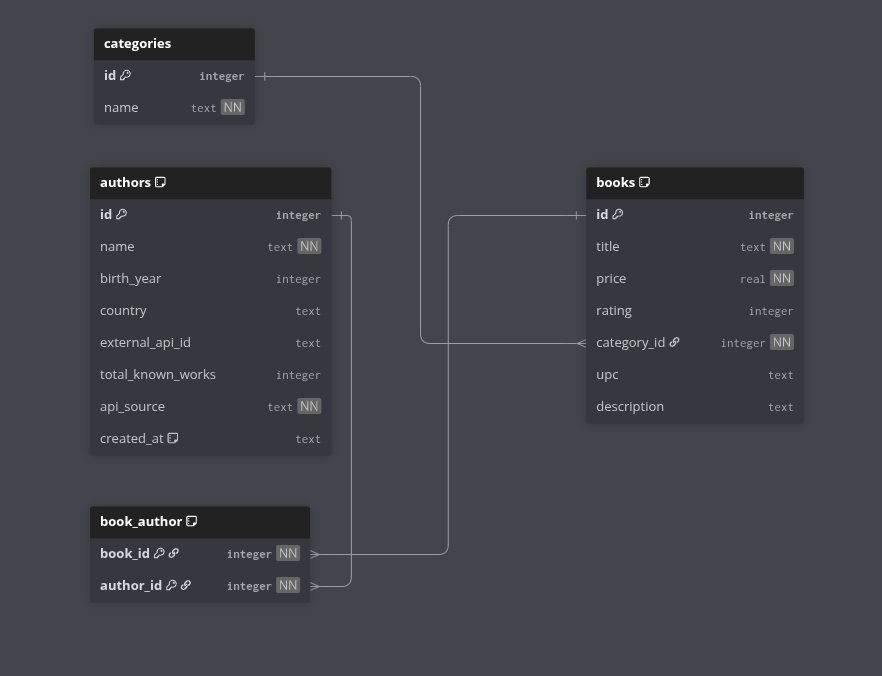

In [1]:
from IPython.display import Image
Image("UML.png")

In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import sqlite3
import time
import os
import re
from urllib.parse import urljoin

BASE_URL = "https://books.toscrape.com/"
DB_PATH = "books_challenge.db"

session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0"
})


## Helpers

In [ ]:
# Hace request y devuelve el HTML parseado
def get_soup(url, timeout=20):
    try:
        response = session.get(url, timeout=timeout)
        # valida errores HTTP:
        response.raise_for_status()
        return BeautifulSoup(response.text, "html.parser")
    except Exception as e:
        print(f"Error al pedir {url}: {e}")
        return None


# Normaliza espacios en el texto
def clean_text(text):
    if text is None:
        return None
    return " ".join(text.strip().split())


# Convierte el precio a float
def parse_price(price_text):
    if price_text is None:
        return None


    cleaned = price_text.strip().replace("Â", "").replace("£", "")
    cleaned = cleaned.replace(",", ".")

    match = re.search(r"\d+(?:\.\d+)?", cleaned)
    return float(match.group()) if match else None


# Convierte rating (string CSS) a int
def rating_to_int(star_class):
    mapping = {
        "One": 1,
        "Two": 2,
        "Three": 3,
        "Four": 4,
        "Five": 5
    }
    for key, value in mapping.items():
        if key in star_class:
            return value
    return None


# Extrae la descripción del libro
def get_book_description(product_page_soup):
    description_header = product_page_soup.find("div", id="product_description")
    if not description_header:
        return None

    p = description_header.find_next("p")
    return clean_text(p.text) if p else None

## 1. Scraping de categorías

In [4]:
# Scrapea todas las categorías desde la página principal
def scrape_categories():
    soup = get_soup(BASE_URL)
    categories = []

    # Si falla la request, devuelve lista vacía
    if soup is None:
        return categories

    # Selecciona los links de categorías del sidebar
    category_links = soup.select(".side_categories ul li ul li a")

    for link in category_links:
        name = clean_text(link.text)  # nombre de la categoría
        rel_url = link.get("href")    # URL relativa
        full_url = urljoin(BASE_URL, rel_url)  # URL absoluta

        categories.append({
            "name": name,
            "url": full_url
        })

    return categories


# Ejecuta el scraping y muestra resultados
categories = scrape_categories()
print("Categorías encontradas:", len(categories))
pd.DataFrame(categories).head()

Categorías encontradas: 50


,name,url
0,Travel,https://books.toscrape.com/catalogue/category/...
1,Mystery,https://books.toscrape.com/catalogue/category/...
2,Historical Fiction,https://books.toscrape.com/catalogue/category/...
3,Sequential Art,https://books.toscrape.com/catalogue/category/...
4,Classics,https://books.toscrape.com/catalogue/category/...


## 2. Scraping de todos los libros

In [ ]:
# Scrapea todos los libros de una categoría (incluyendo paginación)
def scrape_books_from_category(category):
    books = []
    next_url = category["url"]  # primera página de la categoría

    while next_url:
        soup = get_soup(next_url)
        if soup is None:
            break  # corta si falla la request

        # Cada libro está en un article
        articles = soup.select("article.product_pod")

        for article in articles:
            h3 = article.find("h3")
            a_tag = h3.find("a")

            title = a_tag.get("title")
            detail_url = urljoin(next_url, a_tag.get("href"))

            # Precio
            price_text = article.select_one(".price_color").text if article.select_one(".price_color") else None
            price = parse_price(price_text)

            # Rating (viene como clase CSS)
            rating = rating_to_int(article.select_one("p.star-rating").get("class", []))

            # Scraping de la página individual del libro
            detail_soup = get_soup(detail_url)
            if detail_soup is None:
                upc = None
                description = None
            else:
                # Extrae UPC desde la tabla
                table = detail_soup.find("table", class_="table table-striped")
                upc = None
                if table:
                    rows = table.find_all("tr")
                    for row in rows:
                        th = clean_text(row.find("th").text)
                        td = clean_text(row.find("td").text)
                        if th == "UPC":
                            upc = td
                            break

                # Descripción del libro
                description = get_book_description(detail_soup)

            # Guarda el libro
            books.append({
                "title": clean_text(title),
                "price": price,
                "rating": rating,
                "category_name": category["name"],
                "book_url": detail_url,
                "upc": upc,
                "description": description
            })

        # Manejo de paginación
        next_button = soup.select_one("li.next a")
        if next_button:
            next_url = urljoin(next_url, next_button.get("href"))
        else:
            next_url = None

    return books


# Recorre todas las categorías y acumula libros
all_books = []
for i, category in enumerate(categories, start=1):
    print(f"Scrapeando categoría {i}/{len(categories)}: {category['name']}")
    all_books.extend(scrape_books_from_category(category))

# DataFrame final
books_df = pd.DataFrame(all_books)
print("Libros encontrados:", len(books_df))
books_df.head()

Scrapeando categoría 1/50: Travel
Scrapeando categoría 2/50: Mystery
Scrapeando categoría 3/50: Historical Fiction
Scrapeando categoría 4/50: Sequential Art
Scrapeando categoría 5/50: Classics
Scrapeando categoría 6/50: Philosophy
Scrapeando categoría 7/50: Romance
Scrapeando categoría 8/50: Womens Fiction
Scrapeando categoría 9/50: Fiction
Scrapeando categoría 10/50: Childrens
Scrapeando categoría 11/50: Religion
Scrapeando categoría 12/50: Nonfiction
Scrapeando categoría 13/50: Music
Scrapeando categoría 14/50: Default
Scrapeando categoría 15/50: Science Fiction
Scrapeando categoría 16/50: Sports and Games
Scrapeando categoría 17/50: Add a comment
Scrapeando categoría 18/50: Fantasy
Scrapeando categoría 19/50: New Adult
Scrapeando categoría 20/50: Young Adult
Scrapeando categoría 21/50: Science
Scrapeando categoría 22/50: Poetry
Scrapeando categoría 23/50: Paranormal
Scrapeando categoría 24/50: Art
Scrapeando categoría 25/50: Psychology
Scrapeando categoría 26/50: Autobiography
Scrap

,title,price,rating,category_name,book_url,upc,description
0,It's Only the Himalayas,45.17,2,Travel,https://books.toscrape.com/catalogue/its-only-...,a22124811bfa8350,"âWherever you go, whatever you do, just . . ..."
1,Full Moon over Noahâs Ark: An Odyssey to Mou...,49.43,4,Travel,https://books.toscrape.com/catalogue/full-moon...,ce60436f52c5ee68,Acclaimed travel writer Rick Antonson sets his...
2,See America: A Celebration of Our National Par...,48.87,3,Travel,https://books.toscrape.com/catalogue/see-ameri...,f9705c362f070608,To coincide with the 2016 centennial anniversa...
3,Vagabonding: An Uncommon Guide to the Art of L...,36.94,2,Travel,https://books.toscrape.com/catalogue/vagabondi...,1809259a5a5f1d8d,With a new foreword by Tim Ferriss â¢Thereâ...
4,Under the Tuscan Sun,37.33,3,Travel,https://books.toscrape.com/catalogue/under-the...,a94350ee74deaa07,A CLASSIC FROM THE BESTSELLING AUTHOR OF UNDER...


## 3. Enriquecimiento con Open Library

Acá **no saco el autor desde Books to Scrape**.  
Busco el libro por título en Open Library y, si hay un resultado razonable, uso:

- nombre del autor
- `author_key`
- datos del endpoint del autor

Si no hay dato coherente, guardo `NULL`.


In [ ]:
author_cache = {}
book_cache = {}
not_found_titles = []

# Mapea gentilicios encontrados en textos de Open Library a países
GENTILICIOS = {
    "american": "United States",
    "british": "United Kingdom",
    "english": "United Kingdom",
    "scottish": "United Kingdom",
    "irish": "Ireland",
    "french": "France",
    "german": "Germany",
    "spanish": "Spain",
    "italian": "Italy",
    "canadian": "Canada",
    "australian": "Australia",
    "russian": "Russia",
    "polish": "Poland",
    "dutch": "Netherlands",
    "swedish": "Sweden",
    "norwegian": "Norway",
    "danish": "Denmark",
    "brazilian": "Brazil",
    "mexican": "Mexico",
    "argentine": "Argentina",
    "japanese": "Japan",
    "chinese": "China",
    "indian": "India"
}


# Extrae bio/descripción del autor desde Open Library
def extract_description_text(data):
    desc = data.get("bio") or data.get("description")
    if isinstance(desc, dict):
        return desc.get("value")
    if isinstance(desc, str):
        return desc
    return None


# Intenta inferir país buscando gentilicios en el texto
def infer_country_from_text(text):
    if not text:
        return None

    text = text.lower()

    for gentilicio, country in GENTILICIOS.items():
        if re.search(rf"\b{re.escape(gentilicio)}\b", text):
            return country

    return None


# Busca un libro en Open Library por título
def search_openlibrary_book(title):
    if title in book_cache:
        return book_cache[title]

    url = "https://openlibrary.org/search.json"
    params = {
        "title": title,
        "limit": 5
    }

    try:
        response = session.get(url, params=params, timeout=20)
        response.raise_for_status()
        data = response.json()
    except Exception as e:
        print(f"Error buscando libro en Open Library: {title} -> {e}")
        book_cache[title] = None
        return None

    docs = data.get("docs", [])
    if not docs:
        book_cache[title] = None
        return None

    title_lower = title.strip().lower()
    selected = None

    # Prioriza coincidencia exacta de título
    for doc in docs:
        api_title = str(doc.get("title", "")).strip().lower()
        if api_title == title_lower:
            selected = doc
            break

    # Si no hay exacta, acepta coincidencia parcial
    if selected is None:
        for doc in docs:
            api_title = str(doc.get("title", "")).strip().lower()
            if title_lower in api_title or api_title in title_lower:
                selected = doc
                break

    # Si no hay coincidencia clara, usa el primer resultado
    if selected is None:
        selected = docs[0]

    book_cache[title] = selected
    return selected


# Obtiene cantidad aproximada de obras del autor desde Open Library
def get_total_known_works(author_key):
    if not author_key:
        return None

    url = f"https://openlibrary.org/authors/{author_key}/works.json"

    try:
        response = session.get(url, timeout=20)

        # Si no existe el endpoint de obras, guarda NULL
        if response.status_code == 404:
            return None

        response.raise_for_status()
        data = response.json()

        return data.get("size")

    except Exception as e:
        print(f"Error buscando obras del autor {author_key}: {e}")
        return None


# Obtiene datos enriquecidos del autor desde Open Library
def get_author_data(author_key):
    if not author_key:
        return {
            "birth_year": None,
            "country": None,
            "external_api_id": None,
            "total_known_works": None,
            "api_source": "Open Library"
        }

    if author_key in author_cache:
        return author_cache[author_key]

    url = f"https://openlibrary.org/authors/{author_key}.json"

    try:
        response = session.get(url, timeout=20)

        # Guarda datos nulos si el autor no existe
        if response.status_code == 404:
            result = {
                "birth_year": None,
                "country": None,
                "external_api_id": author_key,
                "total_known_works": None,
                "api_source": "Open Library"
            }
            author_cache[author_key] = result
            return result

        response.raise_for_status()
        data = response.json()

    except Exception as e:
        print(f"Error buscando autor {author_key}: {e}")
        result = {
            "birth_year": None,
            "country": None,
            "external_api_id": author_key,
            "total_known_works": None,
            "api_source": "Open Library"
        }
        author_cache[author_key] = result
        return result

    # Extrae año de nacimiento válido
    birth_date = data.get("birth_date")
    birth_year = None
    if birth_date:
        match = re.search(r"(\d{4})", str(birth_date))
        if match:
            year = int(match.group(1))
            if 1000 <= year <= 2026:
                birth_year = year

    # Obtiene país directo o lo infiere desde la descripción
    country = None
    if isinstance(data.get("country"), str) and data.get("country").strip():
        country = data.get("country").strip()
    elif isinstance(data.get("nationality"), str) and data.get("nationality").strip():
        country = data.get("nationality").strip()
    else:
        description_text = extract_description_text(data)
        country = infer_country_from_text(description_text)

    # Obtiene cantidad aproximada de obras usando el campo size
    total_known_works = get_total_known_works(author_key)

    result = {
        "birth_year": birth_year,
        "country": country,
        "external_api_id": author_key,
        "total_known_works": total_known_works,
        "api_source": "Open Library"
    }

    author_cache[author_key] = result
    return result


# Enriquece cada libro con autor y metadata desde Open Library
def enrich_books_with_authors(df):
    rows = []

    for _, row in df.iterrows():
        title = row["title"]
        ol_book = search_openlibrary_book(title)

        # Si no hay match del libro, guarda NULLs
        if ol_book is None:
            not_found_titles.append(title)
            rows.append({
                **row.to_dict(),
                "author_name": None,
                "author_key": None,
                "birth_year": None,
                "country": None,
                "external_api_id": None,
                "total_known_works": None,
                "api_source": "Open Library"
            })
            continue

        author_names = ol_book.get("author_name", [])
        author_keys = ol_book.get("author_key", [])

        # Toma el primer autor devuelto por la API
        author_name = author_names[0] if author_names else None
        author_key = author_keys[0] if author_keys else None

        author_data = get_author_data(author_key)

        rows.append({
            **row.to_dict(),
            "author_name": author_name,
            "author_key": author_key,
            "birth_year": author_data["birth_year"],
            "country": author_data["country"],
            "external_api_id": author_data["external_api_id"],
            "total_known_works": author_data["total_known_works"],
            "api_source": author_data["api_source"]
        })

    return pd.DataFrame(rows)


# Ejecuta el enriquecimiento con la API
enriched_df = enrich_books_with_authors(books_df)
print("Libros enriquecidos:", len(enriched_df))
print("Títulos sin match en Open Library:", len(not_found_titles))
enriched_df.head()

Libros enriquecidos: 1000
Títulos sin match en Open Library: 534


,title,price,rating,category_name,book_url,upc,description,author_name,author_key,birth_year,country,external_api_id,total_known_works,api_source
0,It's Only the Himalayas,45.17,2,Travel,https://books.toscrape.com/catalogue/its-only-...,a22124811bfa8350,"âWherever you go, whatever you do, just . . ...",S. Bedford,OL8084708A,NaN,NaN,OL8084708A,1.0,Open Library
1,Full Moon over Noahâs Ark: An Odyssey to Mou...,49.43,4,Travel,https://books.toscrape.com/catalogue/full-moon...,ce60436f52c5ee68,Acclaimed travel writer Rick Antonson sets his...,NaN,NaN,NaN,NaN,NaN,NaN,Open Library
2,See America: A Celebration of Our National Par...,48.87,3,Travel,https://books.toscrape.com/catalogue/see-ameri...,f9705c362f070608,To coincide with the 2016 centennial anniversa...,NaN,NaN,NaN,NaN,NaN,NaN,Open Library
3,Vagabonding: An Uncommon Guide to the Art of L...,36.94,2,Travel,https://books.toscrape.com/catalogue/vagabondi...,1809259a5a5f1d8d,With a new foreword by Tim Ferriss â¢Thereâ...,NaN,NaN,NaN,NaN,NaN,NaN,Open Library
4,Under the Tuscan Sun,37.33,3,Travel,https://books.toscrape.com/catalogue/under-the...,a94350ee74deaa07,A CLASSIC FROM THE BESTSELLING AUTHOR OF UNDER...,Frances Mayes,OL20984A,1940.0,United States,OL20984A,46.0,Open Library


## 4. Creación de la base de datos SQLite

In [9]:
# Si ya existe la base de datos, la elimina para empezar desde cero
if os.path.exists(DB_PATH):
    os.remove(DB_PATH)

# Crea conexión a SQLite y cursor para ejecutar queries
conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

# Ejecuta todo el DDL de una vez
cur.executescript("""
PRAGMA foreign_keys = ON;  -- habilita integridad referencial

-- Tabla de categorías
CREATE TABLE categories (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    name TEXT NOT NULL UNIQUE
);

-- Tabla de libros
CREATE TABLE books (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    title TEXT NOT NULL,
    price REAL NOT NULL,
    rating INTEGER,
    category_id INTEGER NOT NULL,
    upc TEXT,
    description TEXT,
    FOREIGN KEY (category_id) REFERENCES categories(id)
);

-- Tabla de autores (enriquecidos desde API)
CREATE TABLE authors (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    name TEXT NOT NULL,
    birth_year INTEGER,
    country TEXT,
    external_api_id TEXT,
    total_known_works INTEGER,
    api_source TEXT NOT NULL,
    created_at TEXT DEFAULT CURRENT_TIMESTAMP
);

-- Tabla intermedia (muchos a muchos)
CREATE TABLE book_author (
    book_id INTEGER NOT NULL,
    author_id INTEGER NOT NULL,
    PRIMARY KEY (book_id, author_id),
    FOREIGN KEY (book_id) REFERENCES books(id),
    FOREIGN KEY (author_id) REFERENCES authors(id)
);

-- Índices para mejorar performance de joins y búsquedas
CREATE INDEX idx_books_category_id ON books(category_id);
CREATE INDEX idx_authors_external_api_id ON authors(external_api_id);
CREATE INDEX idx_book_author_book_id ON book_author(book_id);
CREATE INDEX idx_book_author_author_id ON book_author(author_id);
""")

conn.commit()

print("Base creada:", DB_PATH)

Base creada: books_challenge.db


## 5. Inserts

In [10]:
# Inserta categorías y guarda sus IDs para relacionarlas con libros
category_ids = {}
for category_name in sorted(enriched_df["category_name"].dropna().unique()):
    cur.execute("INSERT INTO categories (name) VALUES (?)", (category_name,))
    category_ids[category_name] = cur.lastrowid


# Inserta autores únicos
author_ids = {}
authors_unique = (
    enriched_df[[
        "author_name", "birth_year", "country",
        "external_api_id", "total_known_works", "api_source"
    ]]
    .drop_duplicates()
)

for _, row in authors_unique.iterrows():
    name = row["author_name"] if pd.notna(row["author_name"]) else "Unknown Author"

    cur.execute(
        """
        INSERT INTO authors (
            name, birth_year, country, external_api_id, total_known_works, api_source
        ) VALUES (?, ?, ?, ?, ?, ?)
        """,
        (
            name,
            None if pd.isna(row["birth_year"]) else int(row["birth_year"]),
            None if pd.isna(row["country"]) else row["country"],
            None if pd.isna(row["external_api_id"]) else row["external_api_id"],
            None if pd.isna(row["total_known_works"]) else int(row["total_known_works"]),
            row["api_source"]
        )
    )

    # Clave para identificar autor sin duplicarlo
    key = (
        name,
        None if pd.isna(row["external_api_id"]) else row["external_api_id"]
    )
    author_ids[key] = cur.lastrowid


# Inserta libros y crea la relación libro-autor
for _, row in enriched_df.iterrows():
    cur.execute(
        """
        INSERT INTO books (title, price, rating, category_id, upc, description)
        VALUES (?, ?, ?, ?, ?, ?)
        """,
        (
            row["title"],
            float(row["price"]),
            None if pd.isna(row["rating"]) else int(row["rating"]),
            category_ids[row["category_name"]],
            row["upc"],
            row["description"]
        )
    )
    book_id = cur.lastrowid

    author_name = row["author_name"] if pd.notna(row["author_name"]) else "Unknown Author"
    author_key = None if pd.isna(row["external_api_id"]) else row["external_api_id"]
    author_id = author_ids[(author_name, author_key)]

    cur.execute(
        "INSERT OR IGNORE INTO book_author (book_id, author_id) VALUES (?, ?)",
        (book_id, author_id)
    )

conn.commit()


# Verifica cantidad de registros insertados
print("Categorías:", cur.execute("SELECT COUNT(*) FROM categories").fetchone()[0])
print("Libros:", cur.execute("SELECT COUNT(*) FROM books").fetchone()[0])
print("Autores:", cur.execute("SELECT COUNT(*) FROM authors").fetchone()[0])
print("Relaciones:", cur.execute("SELECT COUNT(*) FROM book_author").fetchone()[0])

Categorías: 50
Libros: 1000
Autores: 404
Relaciones: 1000


## 6. Prueba de que los datos del autor vienen de la API

Se muestran columnas que no existen en Books to Scrape y que fueron enriquecidas con Open Library.


In [11]:
query_api_proof = """
SELECT 
    a.name,
    a.birth_year,
    a.country,
    a.external_api_id,
    a.total_known_works,
    a.api_source
FROM authors a
ORDER BY a.id
LIMIT 10;
"""

pd.read_sql_query(query_api_proof, conn)


,name,birth_year,country,external_api_id,total_known_works,api_source
0,S. Bedford,NaN,NaN,OL8084708A,1.0,Open Library
1,Unknown Author,NaN,NaN,NaN,NaN,Open Library
2,Frances Mayes,1940.0,United States,OL20984A,46.0,Open Library
3,Marilyn Brant,NaN,NaN,OL6792839A,14.0,Open Library
4,Paul Theroux,1941.0,NaN,OL4416468A,264.0,Open Library
5,Patricia Schultz,NaN,NaN,OL2625971A,60.0,Open Library
6,Gillian Flynn,1971.0,NaN,OL1433006A,43.0,Open Library
7,Ruth Ware,1977.0,United Kingdom,OL7764121A,50.0,Open Library
8,Jackson Burnett,NaN,NaN,OL10495431A,1.0,Open Library
9,Julie McElwain,NaN,NaN,OL7290448A,12.0,Open Library


## 7. Consultas pedidas

Mínimo 5 consultas útiles comentadas.


In [12]:
# 1) Libros con más de 3 estrellas por menos de £10
q1 = """
SELECT b.title, b.price, b.rating, c.name AS category
FROM books b
JOIN categories c ON b.category_id = c.id
WHERE b.rating > 3
  AND b.price < 10
ORDER BY b.rating DESC, b.price ASC;
"""
# Ejecuta y muestra resultados
df_q1 = pd.read_sql_query(q1, conn)
print("Consulta 1")
display(df_q1.head(10))


# 2) Autor con peor promedio de rating (mínimo 5 libros)
q2 = """
SELECT 
    a.name,
    COUNT(*) AS total_books,
    ROUND(AVG(b.rating), 2) AS avg_rating
FROM authors a
JOIN book_author ba ON a.id = ba.author_id
JOIN books b ON ba.book_id = b.id
GROUP BY a.id, a.name
HAVING COUNT(*) >= 5
ORDER BY avg_rating ASC, total_books DESC
LIMIT 1;
"""
# Calcula el autor con peor promedio cumpliendo el mínimo de libros
df_q2 = pd.read_sql_query(q2, conn)
print("Consulta 2")
display(df_q2)


# 3) Categoría con mayor precio promedio
q3 = """
SELECT 
    c.name AS category,
    ROUND(AVG(b.price), 2) AS avg_price
FROM categories c
JOIN books b ON c.id = b.category_id
GROUP BY c.id, c.name
ORDER BY avg_price DESC
LIMIT 1;
"""
# Obtiene la categoría más cara en promedio
df_q3 = pd.read_sql_query(q3, conn)
print("Consulta 3")
display(df_q3)


# 4) Top 5 autores con más libros
q4 = """
SELECT 
    a.name,
    COUNT(*) AS total_books
FROM authors a
JOIN book_author ba ON a.id = ba.author_id
GROUP BY a.id, a.name
ORDER BY total_books DESC, a.name ASC
LIMIT 5;
"""
# Lista los autores con mayor cantidad de libros
df_q4 = pd.read_sql_query(q4, conn)
print("Consulta 4")
display(df_q4)


# 5) Consulta obligatoria por país:
# Cuenta libros con rating > 3 agrupados por país del autor
q5 = """
SELECT 
    COALESCE(a.country, 'NULL') AS country,
    COUNT(*) AS total_books
FROM books b
JOIN book_author ba ON b.id = ba.book_id
JOIN authors a ON ba.author_id = a.id
WHERE b.rating > 3
GROUP BY COALESCE(a.country, 'NULL')
ORDER BY total_books DESC, country ASC
LIMIT 10;
"""
# Resultado final requerido por el challenge
df_q5 = pd.read_sql_query(q5, conn)
print("Consulta 5")
display(df_q5)


Consulta 1


,title,price,rating,category


Consulta 2


,name,total_books,avg_rating
0,Worth Books,9,2.33


Consulta 3


,category,avg_price
0,Suspense,58.33


Consulta 4


,name,total_books
0,Unknown Author,546
1,Worth Books,9
2,Stephen King,8
3,David Levithan,4
4,David Sedaris,4


Consulta 5


,country,total_books
0,NULL,328
1,United States,27
2,United Kingdom,13
3,Canada,2
4,France,2
5,Germany,1
6,Ireland,1
7,Netherlands,1


## 8. Performance e indexación

Voy a usar una consulta a propósito sobre `authors.country`.
Primero la corro sin índice específico, después creo el índice y comparo tiempos.


In [13]:
# Consulta usada para medir performance antes y después de agregar un índice
slow_query = """
SELECT 
    a.country,
    COUNT(*) AS total_books,
    ROUND(AVG(b.price), 2) AS avg_price
FROM authors a
JOIN book_author ba ON a.id = ba.author_id
JOIN books b ON ba.book_id = b.id
WHERE a.country IS NOT NULL
GROUP BY a.country
ORDER BY total_books DESC;
"""

# Mide tiempo antes del índice
start = time.perf_counter()
before_df = pd.read_sql_query(slow_query, conn)
time_before = time.perf_counter() - start

print("Tiempo antes del índice:", time_before)
display(before_df.head())


# Crea índice sobre country para optimizar el filtro y agrupamiento
cur.execute("CREATE INDEX IF NOT EXISTS idx_authors_country ON authors(country);")
conn.commit()


# Mide tiempo después del índice
start = time.perf_counter()
after_df = pd.read_sql_query(slow_query, conn)
time_after = time.perf_counter() - start

print("Tiempo después del índice:", time_after)
display(after_df.head())

Tiempo antes del índice: 0.002006003000133205


,country,total_books,avg_price
0,United States,75,36.69
1,United Kingdom,33,32.23
2,France,3,29.81
3,Canada,3,27.95
4,Ireland,2,41.19


Tiempo después del índice: 0.0021520190020964947


,country,total_books,avg_price
0,United States,75,36.69
1,United Kingdom,33,32.23
2,France,3,29.81
3,Canada,3,27.95
4,Ireland,2,41.19


### Explicación breve

Si el segundo tiempo baja, aunque sea un poco, es porque SQLite puede ubicar más rápido los autores por país usando el índice en vez de revisar toda la tabla.

En una base chica puede que la diferencia no sea enorme, pero el objetivo del challenge es mostrar el **antes y después** y explicar la mejora.


## 9. Cierre

Este notebook deja:

- scraping completo del sitio
- enriquecimiento de autores con Open Library
- base SQLite creada desde cero
- inserts hechos
- consultas pedidas
- medición antes y después del índice

Cuando termines, acordate de adjuntar también el **UML** aparte.
